In [3]:


import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import sys
from torch import nn
from torchvision import models

In [4]:
import torch
from torch import nn
from torchvision import models

# Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(SEBlock, self).__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels // reduction, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels // reduction, in_channels, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        scale = self.se(x)
        return x * scale

# Spatial Attention Block
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attn = torch.cat([avg_out, max_out], dim=1)
        attn = self.conv(attn)
        return x * self.sigmoid(attn)

class EnhancedModel(nn.Module):
    def __init__(self, num_classes, latent_dim=2048, lstm_layers=1, hidden_dim=2048, bidirectional=False):
        super(EnhancedModel, self).__init__()

        # Feature extractor
        base_model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-2])
        
        # SE block + Spatial attention
        self.se = SEBlock(2048)
        self.spatial_attn = SpatialAttention()
        self.avgpool = nn.AdaptiveAvgPool2d(1)

        # LSTM
        self.lstm = nn.LSTM(latent_dim, hidden_dim, lstm_layers, batch_first=True, bidirectional=bidirectional)
        lstm_output_dim = hidden_dim * (2 if bidirectional else 1)
        self.norm = nn.LayerNorm(lstm_output_dim)

        # Classifier with residual connection
        self.fc1 = nn.Linear(lstm_output_dim, lstm_output_dim)
        self.act = nn.GELU()
        self.dp = nn.Dropout(0.4)
        self.fc2 = nn.Linear(lstm_output_dim, num_classes)

    def forward(self, x):
        batch_size, seq_len, c, h, w = x.shape

        # CNN feature extraction
        x = x.view(batch_size * seq_len, c, h, w)
        fmap = self.feature_extractor(x)                     # (B*T, 2048, H', W')
        x = self.se(fmap)
        x = self.spatial_attn(x)
        x = self.avgpool(x)
        x = x.view(batch_size, seq_len, -1)                  # (B, T, 2048)

        # LSTM
        x_lstm, _ = self.lstm(x)                             # (B, T, H)
        x_lstm = self.norm(x_lstm)

        # Temporal aggregation
        x_mean = x_lstm.mean(dim=1)

        # Residual classifier
        residual = x_mean
        x_out = self.fc1(x_mean)
        x_out = self.act(x_out)
        x_out = self.dp(x_out)
        x_out = x_out + residual                             # Residual connection
        logits = self.fc2(x_out)

        return fmap, logits


In [5]:
im_size = 112
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]
sm = nn.Softmax(dim=1)
inv_normalize =  transforms.Normalize(mean=-1*np.divide(mean,std),std=np.divide([1,1,1],std))
def im_convert(tensor):
    """ Display a tensor as an image. """
    image = tensor.to("cpu").clone().detach()
    image = image.squeeze()
    image = inv_normalize(image)
    image = image.numpy()
    image = image.transpose(1,2,0)
    image = image.clip(0, 1)
    cv2.imwrite('./2.png',image*255)
    return image

import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch.nn.functional as F

def predict(model, img, path='./'):
    model.to(device)
    img = img.to(device)

    with torch.no_grad():
        fmap, logits = model(img)
    params = list(model.parameters())
    weight_softmax = model.linear1.weight.detach().cpu().numpy()

    logits = F.softmax(logits, dim=1)
    _, prediction = torch.max(logits, 1)
    confidence = logits[:, int(prediction.item())].item() * 100
    print('confidence of prediction:', confidence)

    idx = np.argmax(logits.detach().cpu().numpy())
    bz, nc, h, w = fmap.shape
    out = np.dot(fmap[-1].detach().cpu().numpy().reshape((nc, h * w)).T,
                 weight_softmax[idx, :].T)
    
    predict = out.reshape(h, w)
    predict = predict - np.min(predict)
    predict_img = predict / np.max(predict)
    predict_img = np.uint8(255 * predict_img)
    im_size = img.shape[-1]
    out = cv2.resize(predict_img, (im_size, im_size))
    heatmap = cv2.applyColorMap(out, cv2.COLORMAP_JET)

    img_np = im_convert(img[:, -1, :, :, :])  # Make sure im_convert is defined for CPU

    result = heatmap * 0.5 + img_np * 0.8 * 255
    cv2.imwrite(f'{path}/1.png', result)

    result1 = heatmap * 0.5 / 255 + img_np * 0.8
    r, g, b = cv2.split(result1)
    result1 = cv2.merge((r, g, b))
    plt.imshow(result1)
    plt.axis('off')
    plt.show()

    return [int(prediction.item()), confidence]

#img = train_data[100][0].unsqueeze(0)
#predict(model,img)

In [6]:
def enhanced_predict(model, img, path='./'):
    model.to(device)
    img = img.to(device)

    with torch.no_grad():
        fmap, logits = model(img)
    weight_softmax = model.fc2.weight.detach().cpu().numpy()  # Changed to fc2

    # Prediction and confidence
    logits = F.softmax(logits, dim=1)
    _, prediction = torch.max(logits, 1)
    confidence = logits[:, int(prediction.item())].item() * 100
    print('confidence of prediction:', confidence)

    # Feature map processing
    idx = np.argmax(logits.detach().cpu().numpy())
    bz, nc, h, w = fmap.shape
    out = np.dot(fmap[-1].detach().cpu().numpy().reshape((nc, h*w)).T,
                 weight_softmax[idx, :].T)  # Use fc2 weights

    # Heatmap generation
    predict = out.reshape(h, w)
    predict = (predict - np.min(predict)) / (np.max(predict) - np.min(predict))
    predict_img = np.uint8(255 * predict)
    im_size = img.shape[-1]
    out = cv2.resize(predict_img, (im_size, im_size))
    heatmap = cv2.applyColorMap(out, cv2.COLORMAP_JET)

    # Image overlay
    img_np = im_convert(img[:, -1, :, :, :])
    result = heatmap * 0.5 + img_np * 0.8 * 255
    cv2.imwrite(f'{path}/enhanced_heatmap.png', result)

    # Matplotlib visualization
    result1 = heatmap * 0.5/255 + img_np * 0.8
    r, g, b = cv2.split(result1)
    result1 = cv2.merge((r, g, b))
    plt.imshow(result1)
    plt.axis('off')
    plt.show()

    return [int(prediction.item()), confidence]

In [ ]:
import torch
from torchvision import transforms
from torch.utils.data.dataset import Dataset
import numpy as np
import cv2
import matplotlib.pyplot as plt

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

class validation_dataset(Dataset):
    """Returns a (1, T, 3, 112, 112) tensor per video.

    crop_faces=True  -> raw video: crop the face in each frame with the Haar Cascade
                        (same settings as preprocessing); frames without a face are kept whole.
    crop_faces=False -> video is already face-cropped (e.g. *_face_videos/): use frames as-is.
    """
    def __init__(self, video_names, sequence_length=60, transform=None, crop_faces=True):
        self.video_names = video_names
        self.transform = transform
        self.count = sequence_length
        self.crop_faces = crop_faces
    def __len__(self):
        return len(self.video_names)
    def __getitem__(self, idx):
        video_path = self.video_names[idx]
        frames = []
        for frame in self.frame_extract(video_path):
            if self.crop_faces:
                gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(50, 50))
                if len(faces) > 0:
                    x, y, w, h = faces[0]
                    frame = frame[y:y+h, x:x+w]
            frames.append(self.transform(frame))
            if len(frames) == self.count:
                break
        frames = torch.stack(frames)
        return frames.unsqueeze(0)
    def frame_extract(self, path):
        vidObj = cv2.VideoCapture(path)
        success = 1
        while success:
            success, image = vidObj.read()
            if success:
                yield image
        vidObj.release()

def im_plot(tensor):
    image = tensor.cpu().numpy().transpose(1,2,0)
    b,g,r = cv2.split(image)
    image = cv2.merge((r,g,b))
    image = image*[0.22803, 0.22145, 0.216989] +  [0.43216, 0.394666, 0.37645]
    image = image*255.0
    plt.imshow(image.astype(int))
    plt.show()


In [ ]:
#Code for making prediction
im_size = 112
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
                                        transforms.ToPILImage(),
                                        transforms.Resize((im_size,im_size)),
                                        transforms.ToTensor(),
                                        transforms.Normalize(mean,std)])

import torch
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")

model = EnhancedModel(2).to(device)
print(f"Using device: {device}")

path_to_model = './final_model/checkpoint3.pt'
model.load_state_dict(torch.load(path_to_model, map_location=device))



Using device: mps


<All keys matched successfully>

PREDICTOR

./real_yt/130.mp4


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.012549050152301788..1.2121568322181702].


confidence of prediction: 98.47495555877686


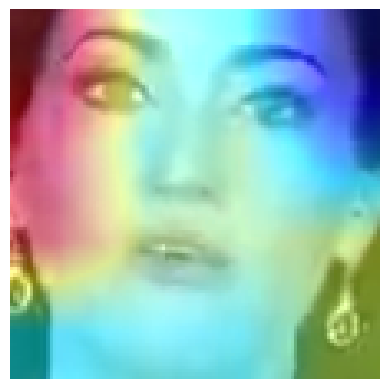

REAL
real_yt/229.mp4


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00941175315529108..1.268627405166626].


confidence of prediction: 80.65492510795593


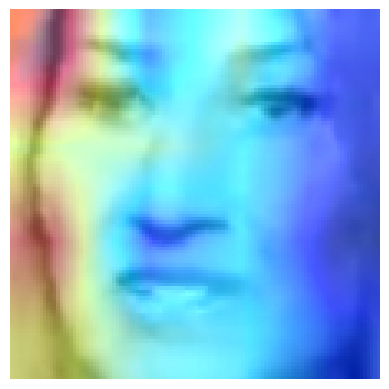

REAL
fake_yt/042_084.mp4


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1650980710983276].


confidence of prediction: 97.66154289245605


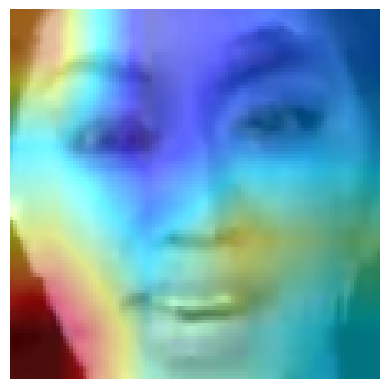

FAKE
fake_yt/295_099.mp4


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1380392611026764..1.268627405166626].


confidence of prediction: 50.44037103652954


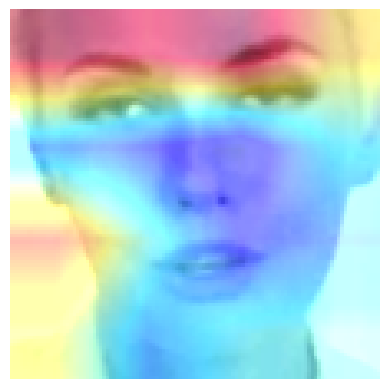

FAKE


In [25]:
path_to_videos= ["./real_yt/130.mp4", 'real_yt/229.mp4', 'fake_yt/042_084.mp4', 'fake_yt/295_099.mp4']
video_dataset = validation_dataset(path_to_videos,sequence_length = 20,transform = train_transforms, crop_faces=True)


model.eval()
for i in range(0,len(path_to_videos)):
  print(path_to_videos[i])
  prediction = enhanced_predict(model,video_dataset[i],'./')
  if prediction[0] == 1:
    print("REAL")
  else:
    print("FAKE")

In [ ]:

path_to_videos= ["./real_yt_face_videos/130.mp4", 'real_yt_face_videos/229.mp4', 'fake_yt_face_videos/042_084.mp4', 'fake_yt_face_videos/295_099.mp4']
video_dataset = validation_dataset(path_to_videos,sequence_length = 20,transform = train_transforms, crop_faces=False)


model.eval()
for i in range(0,len(path_to_videos)):
  print(path_to_videos[i])
  prediction = enhanced_predict(model,video_dataset[i],'./')
  if prediction[0] == 1:
    print("REAL")
  else:
    print("FAKE")


## Baseline comparison

The original ResNeXt-LSTM model (no attention) on the same videos.


In [ ]:
#Model with feature visualization
from torch import nn
from torchvision import models
class Model(nn.Module):
    def __init__(self, num_classes,latent_dim= 2048, lstm_layers=1 , hidden_dim = 2048, bidirectional = False):
        super(Model, self).__init__()
        model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1) #Residual Network CNN
        self.model = nn.Sequential(*list(model.children())[:-2])
        self.lstm = nn.LSTM(latent_dim,hidden_dim, lstm_layers,  bidirectional)  # NB: 4th positional arg is `bias`; kept as-is so saved checkpoints still load
        self.relu = nn.LeakyReLU()
        self.dp = nn.Dropout(0.4)
        self.linear1 = nn.Linear(2048,num_classes)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
    def forward(self, x):
        batch_size,seq_length, c, h, w = x.shape
        x = x.view(batch_size * seq_length, c, h, w)
        fmap = self.model(x)
        x = self.avgpool(fmap)
        x = x.view(batch_size,seq_length,2048)
        x_lstm,_ = self.lstm(x,None)
        return fmap,self.dp(self.linear1(torch.mean(x_lstm,dim = 1)))

In [ ]:
model = Model(2).to(device)
print(f"Using device: {device}")

path_to_model = './model/checkpoint3.pt'
model.load_state_dict(torch.load(path_to_model, map_location=device))



model.eval()
for i in range(0,len(path_to_videos)):
  print(path_to_videos[i])
  prediction = predict(model,video_dataset[i],'./')
  if prediction[0] == 1:
    print("REAL")
  else:
    print("FAKE")